In [1]:
import numpy as np
from pathlib import Path
import os,sys
from tqdm import tqdm
import matplotlib.pyplot as plt
import glob
from scipy.spatial.distance import squareform, pdist
import hdbscan
from vedo import Arrow, Plotter
import vedo
vedo.settings.default_backend= 'vtk'
import pickle

shard = "Carboxamid_start_atm"

#paths = glob.glob("../data/sabdab/interfaces/{shard}/data_by_pdb/*.npz")
paths = glob.glob(f"/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/{shard}/data_by_pdb/*.npz")
#paths
MAX_NEIGHBOURS = 25


In [2]:

def kabsch_align(A, B):
    """
    Aligns A to B using the Kabsch algorithm.
    Returns rotated A and the RMSD.
    """
    assert A.shape == B.shape, "Shapes must match"
    
    # Center both sets
    A_centered = A - A.mean(axis=0)
    B_centered = B - B.mean(axis=0)
    
    # Compute covariance matrix
    H = A_centered.T @ B_centered
    
    # SVD
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T
    
    # Correct for reflection
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T

    # Apply rotation to A
    A_rot = A_centered @ R
    
    # RMSD
    rmsd = np.sqrt(np.mean(np.sum((A_rot - B_centered) ** 2, axis=1)))
    
    return A_rot, rmsd




def pad_array(arr, target_rows):
    """Pad or trim the array to have exactly target_rows rows."""
    if arr.shape[0] >= target_rows:
        return arr[:target_rows]
    else:
        padding = np.zeros((target_rows - arr.shape[0], arr.shape[1]), dtype=arr.dtype)
        return np.vstack([arr, padding])

def process_triplet(triplet):
    """
    Process a single triplet to extract:
      - target positions (all columns except the first and last)
      - target classes (first column, reshaped as a column vector)
      - chart orientation
    Each of the first two arrays is padded (or trimmed) to have MAX_NEIGHBOURS rows.
    """
    # Extract and pad target positions.
    positions = pad_array(triplet["target_atoms"][:, 1:-1], MAX_NEIGHBOURS)
    
    # Extract and pad target classes.
    target_atms = triplet["target_atoms"][:, 0] #+1 <--  from old version, problem with zero padding now handled in map_atoms()
    #print(target_atms)
    classes = pad_array(target_atms.reshape(-1, 1), MAX_NEIGHBOURS)
    
    # Extract chart orientation (assumed to be already in the desired shape).
    #chart_ori = triplet["chart_orientation"]
    
    return positions, classes #, chart_ori

def process_files(file_paths):
    """
    Process all files and aggregate the processed triplet information.
    Returns three numpy arrays for positions, classes, and chart orientations.
    """
    target_positions = []
    target_classes = []
    pdbIDs = []
    #chart_orientations = []
    
    for path in file_paths:
        pdbID = Path(path).stem
        try:
            with np.load(path, allow_pickle=True) as data:
                triplets = data["triplets"]
                for triplet in triplets:
                    #positions, classes, chart_ori = process_triplet(triplet)
                    positions, classes = process_triplet(triplet)
                    target_positions.append(positions)
                    target_classes.append(classes)
                    pdbIDs.append(pdbID)
                    #chart_orientations.append(chart_ori)
        except Exception as e:
            print(f"Error loading {path}: {e}")
    
    return (np.stack(target_positions), 
            np.stack(target_classes)), pdbIDs


In [3]:

data, pdbIDs = process_files(paths)
pdbIDs = np.asarray(pdbIDs)


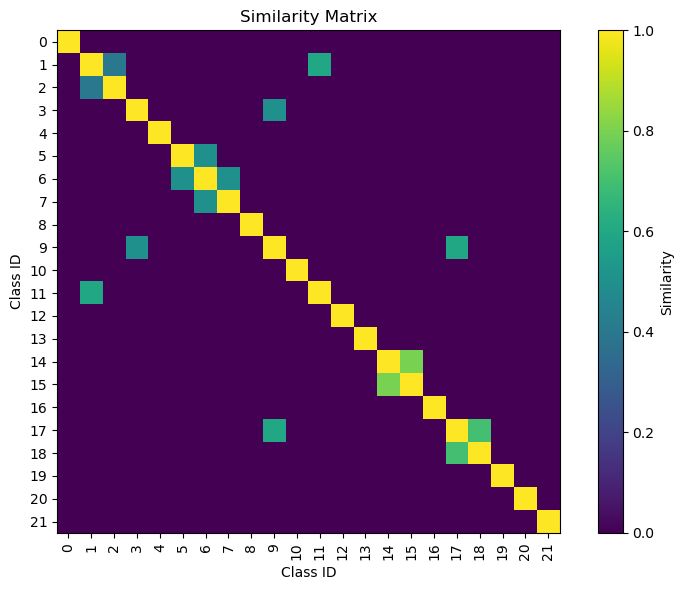

In [4]:
#np.set_printoptions(threshold=np.inf, linewidth=200, suppress=True)
#print("Indices of NaNs:")
#for index in zip(*nan_indices):
#    print(f"{index} : pdbID: {pdbIDs[index[0]]}" )
NUM_CLASSES = 22
similarity_matrix = np.eye(NUM_CLASSES)
similarity_matrix

# Example semantic similarity setup
# sp3 vs sp2 carbon (similar)
similarity_matrix[1, 11] = similarity_matrix[11, 1] = 0.6

# sp3 vs aromatic (less similar)
similarity_matrix[1, 2] = similarity_matrix[2, 1] = 0.4

# oxygen types (alcohol vs carboxyl)
similarity_matrix[5, 6] = similarity_matrix[6, 5] = 0.5
similarity_matrix[6, 7] = similarity_matrix[7, 6] = 0.5

# nitrogen types
similarity_matrix[3, 9] = similarity_matrix[9, 3] = 0.5
similarity_matrix[9, 17] = similarity_matrix[17, 9] = 0.6
similarity_matrix[17, 18] = similarity_matrix[18, 17] = 0.7

# sulfur group
similarity_matrix[14, 15] = similarity_matrix[15, 14] = 0.8
class_labels = list(range(similarity_matrix.shape[0]))  # or your own label names

plt.figure(figsize=(8, 6))
plt.imshow(similarity_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Similarity')

plt.title('Similarity Matrix')
plt.xlabel('Class ID')
plt.ylabel('Class ID')
plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels, rotation=90)
plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)

plt.tight_layout()
plt.grid(False)

plt.show()
ALPHA = 0 # label weight
BETA = 1 # RMSD weight
GAMMA = 0.5     # translation distance weight

def compute_kabsch_rmsd(P, Q):
    # Align P to Q using Kabsch algorithm
    P_centered = P - P.mean(axis=0)
    Q_centered = Q - Q.mean(axis=0)
    H = P_centered.T @ Q_centered
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T
    P_rot = P_centered @ R
    rmsd = np.sqrt(np.mean(np.sum((P_rot - Q_centered) ** 2, axis=1)))
    return rmsd

def custom_distance(a, b):
    """
    HDBSCAN-compatible custom metric.
    a, b: arrays of shape (10, 4), where each row = [x, y, z, label_id]
    """

    # Consider only same sized brooms:

    # Create masks for non-padding entries
    mask_a = ~np.all(a[:, :3] == 0, axis=1)
    mask_b = ~np.all(b[:, :3] == 0, axis=1)
    PADDING_LABEL = 0

    # Check: All zero vectors must have padding label
    if not (
        np.all(a[~mask_a, 3] == PADDING_LABEL) and
        np.all(b[~mask_b, 3] == PADDING_LABEL)
    ):
        raise ValueError(f"Zero-padded vectors must have label == {PADDING_LABEL}")
        
    if a[mask_a].shape[0] != b[mask_b].shape[0]:
        return 1e2


    coords_a = a[:, :3]
    coords_b = b[:, :3]
    labels_a = a[:, 3].astype(int)
    labels_b = b[:, 3].astype(int)

    # Translation-aware part
    centroid_dist = np.linalg.norm(coords_a.mean(axis=0) - coords_b.mean(axis=0))



    # Geometry part: rotational alignment RMSD
    rmsd = compute_kabsch_rmsd(coords_a, coords_b)

    # Label similarity part: mean dissimilarity = (1 - similarity)
    label_dist = np.mean([1.0 - similarity_matrix[i, j] for i, j in zip(labels_a, labels_b)])

    return ALPHA * label_dist + BETA * rmsd + GAMMA * centroid_dist


In [5]:

vectors = data[0]
labels = data[1]

data_array = np.concatenate([vectors, labels], axis=-1)

#for i in range(len(data_array)):
#    print(custom_distance(data_array[0], data_array[i]))

data_array.shape

(50504, 25, 4)

In [8]:
np.where(np.isnan(data_array)) #4cc8 #UNK problem

(array([], dtype=int64), array([], dtype=int64), array([], dtype=int64))

In [3]:
#Pick out specific pdb: 7d3r

np.where(np.asarray(pdbIDs) == "7d3r")

(array([44912, 44913]),)

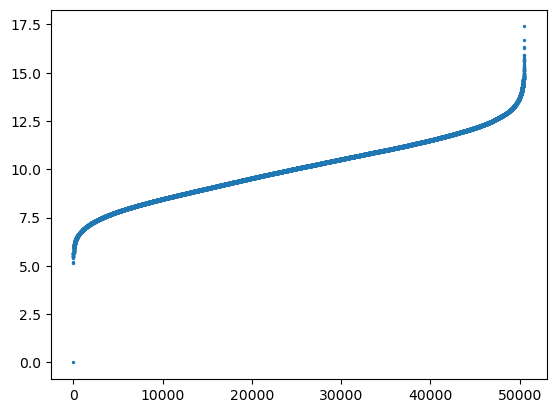

In [6]:
broom_index = 0
#broom_index = 44912
#broom_index = 24

distances = np.zeros(data_array.shape[0])
for i,val in enumerate(distances):
    distances[i] = custom_distance(data_array[broom_index,:,:], data_array[i,:,:])

min_ind = np.argsort(distances)
min_ind
nearest_neigbours = np.asarray(pdbIDs)[min_ind]
nearest_neigbours[:10]
plt.scatter(range(len(distances)), distances[min_ind], s = 2)

In [7]:
distances[min_ind]

array([3.61364670e-07, 5.12528723e+00, 5.21700087e+00, ...,
       1.63201389e+01, 1.66768217e+01, 1.73918815e+01], shape=(50504,))

In [9]:
pdbIDs[min_ind][-5:]

array(['9j83', '8euv', '7ll1', '3j42', '3j42'], dtype='<U4')

In [22]:
#VEDO Plot

# Define a list of 22 for atom types.

colors = [
    "black",  # bright red - stands out for important outliers
    "#377eb8",  # blue
    "#4daf4a",  # green
    "#984ea3",  # purple
    "#ff7f00",  # orange
    "#ffff33",  # yellow
    "#a65628",  # brown
    "#f781bf",  # pink
    "#999999",  # grey
    "#66c2a5",  # teal
    "#fc8d62",  # coral
    "#8da0cb",  # lavender blue
    "#e78ac3",  # orchid
    "#a6d854",  # lime green
    "#ffd92f",  # light yellow
    "#e5c494",  # tan
    "#b3b3b3",  # light grey
    "#1f78b4",  # deep blue
    "#33a02c",  # deep green
    "#6a3d9a",  # dark purple
    "#b15928",  # sienna
    "#cab2d6"   # light purple
]
n_brooms= 6
brooms_ind = min_ind[:n_brooms]


In [23]:
brooms_ind

array([    0,  3489,  5615, 29004, 13559,  5146])

In [24]:

brooms_ind = np.concatenate((brooms_ind, min_ind[-5:]))
#brooms_ind = np.asarray([278, 4124])
brooms_ind

array([    0,  3489,  5615, 29004, 13559,  5146, 24444, 37813, 46904,
       15384, 15382])

In [25]:

x_positions = np.linspace(0,50,len(brooms_ind))
arrows = []


In [15]:
min_ind
print(type(min_ind))

pdbIDs = np.asarray(pdbIDs)
pdbIDs_sorted = pdbIDs[min_ind]

<class 'numpy.ndarray'>


In [1]:
pdbIDs_sorted[:10]   
    
    

    
    

NameError: name 'pdbIDs_sorted' is not defined

In [ ]:

# Loop over each bundle.
for i, x in enumerate(x_positions):
    # Grab the 15 vectors (ch1) and their corresponding one-hot encodings (ch2)
    vectorbundle = vectors[brooms_ind[i],:,:]     # shape: (15, 3)
    encodings = labels[brooms_ind[i],:,:]
    for vec, encoding in zip(vectorbundle, encodings):
        # Optionally, skip vectors which are essentially zero.
        if not np.allclose(vec, 0):
            start_pt = [x, 0, 0]
            end_pt   = [x + vec[0], vec[1], vec[2]]
            arrow_color = colors[int(encoding[0])]
            arrows.append(Arrow(start_pt=start_pt, end_pt=end_pt, s=0.02, c=arrow_color))

vp = Plotter(title="Bundles", axes=1)

vp.show(*arrows, interactive=True)




In [3]:
SAMPLE_SIZE = 5000

indices = np.random.permutation(data_array.shape[0])[:SAMPLE_SIZE]
subset = data_array[indices, :,:]

#subset
distance_matrix = np.zeros((SAMPLE_SIZE, SAMPLE_SIZE))

for i in tqdm(range(SAMPLE_SIZE)):
    for j in range(i + 1, SAMPLE_SIZE):
        d = custom_distance(subset[i], subset[j])
        distance_matrix[i, j] = d
        distance_matrix[j, i] = d



  0%|          | 0/5000 [00:00<?, ?it/s]

100%|██████████| 5000/5000 [13:51<00:00,  6.01it/s] 


In [ ]:
with open("example5000_distance_matrix.pkl", "rb") as f:
    distance_matrix = pickle.load(f)

with open("example5000_indices.pkl", "rb") as f:
    distance_matrix = pickle.load(f)

In [ ]:
#with open("sample5000_distance_matrix.pkl", "wb") as f:
#    pickle.dump(distance_matrix,f)

In [ ]:


np.set_printoptions(threshold=np.inf, linewidth=200, suppress=True)
distance_matrix

In [44]:
np.sum(distance_matrix == 0)

np.int64(1000)

In [6]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(metric="precomputed", radius = 10, n_neighbors= 10)


In [5]:
data_array.shape

(50700, 25, 4)

In [7]:
nn.fit(distance_matrix)


,n_neighbors,10
,radius,10
,algorithm,'auto'
,leaf_size,30
,metric,'precomputed'
,p,2
,metric_params,None
,n_jobs,None


In [21]:
subset.shape

(1000, 25, 4)

In [9]:
distances, indices = nn.kneighbors(distance_matrix)


In [10]:
distances

array([[0.        , 5.81585205, 6.27296436, ..., 6.67164493, 6.70953286,
        6.8573606 ],
       [0.        , 4.9782812 , 6.06937373, ..., 6.36535758, 6.37268853,
        6.42544109],
       [0.        , 5.30132604, 5.68499565, ..., 5.99171877, 5.99592435,
        6.02424657],
       ...,
       [0.        , 4.90898514, 5.13509786, ..., 5.98724264, 5.99962592,
        6.00214529],
       [0.        , 7.18846154, 7.30754709, ..., 7.92309546, 7.97331405,
        8.02994806],
       [0.        , 6.76356947, 6.81495446, ..., 7.0956459 , 7.14227331,
        7.17946506]], shape=(5000, 10))

In [11]:
indices

array([[   0, 4641,  925, ...,  772,  993, 2756],
       [   1,  383, 1032, ...,  474, 2312, 2641],
       [   2, 3615,  810, ...,  712,  746, 4265],
       ...,
       [4997,  925,  430, ..., 3701,  582,  764],
       [4998, 4610, 1699, ..., 3330, 1827, 1065],
       [4999, 4850, 3688, ..., 1636,  814, 3435]], shape=(5000, 10))

In [14]:
distance_threshold = 2

similar_groups = {
    i: [j for j, d in zip(indices[i], distances[i]) if d < distance_threshold and j != i]
    for i in range(len(distances))
}

In [15]:
similar_groups

{0: [],
 1: [],
 2: [],
 3: [],
 4: [],
 5: [],
 6: [],
 7: [],
 8: [],
 9: [],
 10: [],
 11: [],
 12: [],
 13: [],
 14: [],
 15: [],
 16: [],
 17: [],
 18: [],
 19: [],
 20: [],
 21: [],
 22: [],
 23: [],
 24: [],
 25: [],
 26: [],
 27: [],
 28: [],
 29: [],
 30: [],
 31: [],
 32: [],
 33: [],
 34: [],
 35: [],
 36: [],
 37: [],
 38: [],
 39: [],
 40: [],
 41: [],
 42: [],
 43: [],
 44: [],
 45: [],
 46: [],
 47: [],
 48: [],
 49: [],
 50: [],
 51: [],
 52: [],
 53: [],
 54: [],
 55: [],
 56: [],
 57: [],
 58: [],
 59: [],
 60: [],
 61: [],
 62: [],
 63: [],
 64: [],
 65: [],
 66: [],
 67: [],
 68: [],
 69: [],
 70: [],
 71: [],
 72: [],
 73: [],
 74: [],
 75: [],
 76: [],
 77: [],
 78: [],
 79: [],
 80: [],
 81: [],
 82: [],
 83: [],
 84: [],
 85: [],
 86: [],
 87: [],
 88: [],
 89: [],
 90: [],
 91: [],
 92: [],
 93: [],
 94: [],
 95: [],
 96: [],
 97: [],
 98: [],
 99: [],
 100: [],
 101: [],
 102: [],
 103: [],
 104: [],
 105: [],
 106: [],
 107: [],
 108: [],
 109: [],
 110: [],


/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_18093/4022629564.py:11: UserWarning: No data for col

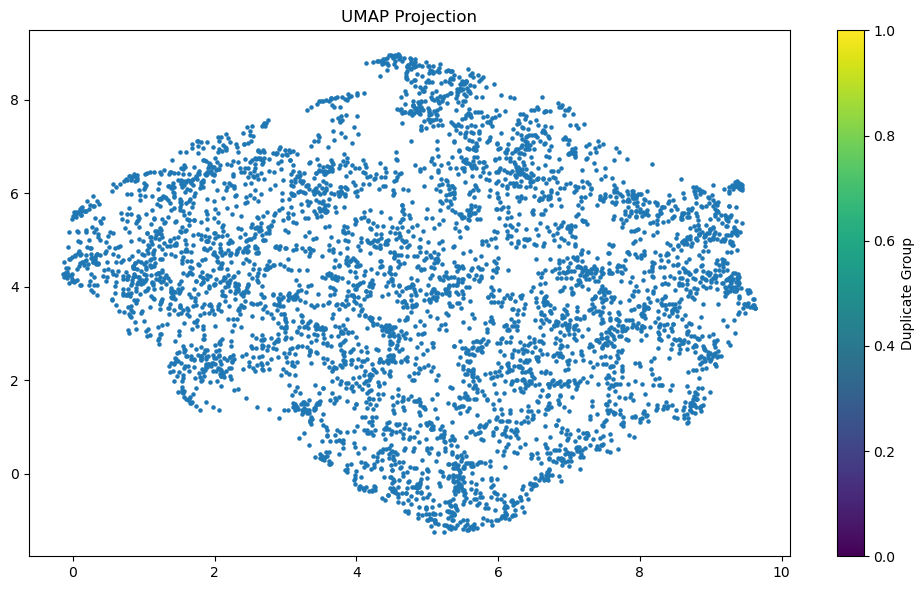

In [16]:
import umap
import matplotlib.pyplot as plt

# Run UMAP on your distance matrix
reducer = umap.UMAP(metric='precomputed', random_state=42)
embedding = reducer.fit_transform(distance_matrix)

# Plot using group labels (same color = duplicate group)
plt.figure(figsize=(10, 6))
#plt.scatter(embedding[:, 0], embedding[:, 1], c=group_labels, cmap='tab20', s=5)
plt.scatter(embedding[:, 0], embedding[:, 1], cmap='tab20', s=5)
plt.colorbar(label="Duplicate Group")
plt.title("UMAP Projection")
plt.tight_layout()
plt.show()

In [4]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=4,
    min_samples=1,            # lower density requirement
    metric='precomputed'
)

clusterer.fit(distance_matrix)

,min_cluster_size,4
,min_samples,1
,cluster_selection_epsilon,0.0
,max_cluster_size,0
,metric,'precomputed'
,alpha,1.0
,p,None
,algorithm,'best'
,leaf_size,40
,memory,Memory(location=None)
,approx_min_span_tree,True


In [5]:
np.unique(clusterer.labels_)

array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32,
       33, 34, 35, 36, 37, 38, 39])

In [6]:
import umap
import matplotlib.pyplot as plt

# Important: tell UMAP you're using a distance matrix
reducer = umap.UMAP(metric='precomputed', n_neighbors=15, min_dist=0.1, random_state=42)

embedding = reducer.fit_transform(distance_matrix)

/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/home/kiemax/anaconda3/envs/hdbscan_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


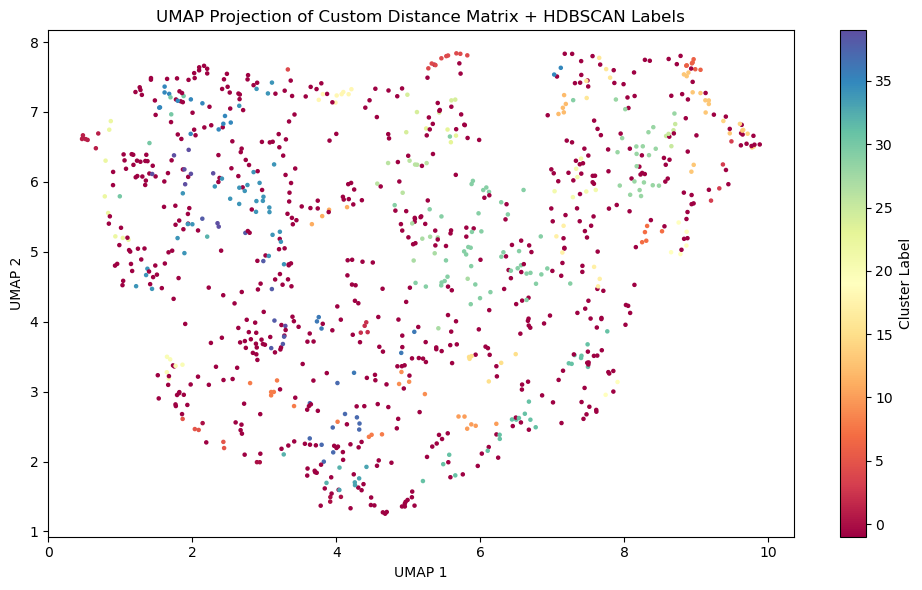

In [7]:
labels = clusterer.labels_  # from HDBSCAN

plt.figure(figsize=(10, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], c=labels, cmap='Spectral', s=5)
plt.colorbar(label='Cluster Label')
plt.title("UMAP Projection of Custom Distance Matrix + HDBSCAN Labels")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.tight_layout()
plt.show()